<a href="https://colab.research.google.com/github/suditikumar/Consumer-Churn-Prediction-MST-AI-project/blob/main/mst_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telco Customer Churn Prediction

## 1. Problem Statement

### Objective
To predict whether a telecom customer will churn based on their demographic, service, contract, and billing information.

### Problem Type
Binary Classification

### Input
Customer demographic, service usage, contract, and billing-related features.

### Output
`Churn` — whether the customer will churn (Yes/No).

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Dataset

The Telco Customer Churn dataset contains customer demographic, service, contract, and billing information.

### Dataset Source
GitHub

### Dataset Type
Real-world customer data

### Number of Records
7,043

### Number of Columns
21

### Target Variable
`Churn`

### Classification
Binary Classification
- Yes → Customer churned
- No → Customer did not churn

## 3. Understanding the Dataset

In [ ]:
# Shape of the dataset
print("Shape of dataset:", df.shape)

# Data types and non-null information
print("\nDataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nNumber of Duplicate Records:", df.duplicated().sum())

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Target variable distribution
print("\nTarget Variable Distribution:")
print(df["Churn"].value_counts())

Shape of dataset: (7043, 21)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   obje

In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


# 4. Data Preprocessing

Data preprocessing is performed to prepare the dataset for machine learning. The following steps are carried out:

1. Handling missing values
2. Checking duplicate records
3. Removing irrelevant features
4. Handling outliers
5. Identifying numerical and categorical features
6. Separating features and target variable
7. Splitting the dataset into training and testing sets
8. Encoding categorical variables and scaling numerical features

In [ ]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


## 4.1 Handling Missing Values

The `TotalCharges` column initially contains 11 blank values. These blank values are converted into missing values using numerical conversion.

Since only 11 out of 7,043 records are affected, the corresponding records are removed rather than assigning estimated values. This avoids introducing artificial billing information into the dataset.

In [ ]:
# Check blank values in TotalCharges
blank_values = df["TotalCharges"].fillna("").astype(str).str.strip().eq("").sum()

print("Blank values in TotalCharges:", blank_values)

Blank values in TotalCharges: 11


In [ ]:
print("Missing values in TotalCharges:", df["TotalCharges"].isna().sum())

Missing values in TotalCharges: 0


In [ ]:
import pandas as pd

df = pd.read_csv('/content/Telco-Customer-Churn.csv')

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing values in TotalCharges:", df["TotalCharges"].isna().sum())

Missing values in TotalCharges: 11


In [ ]:
df = df.dropna(subset=["TotalCharges"])

print("Missing values after cleaning:", df["TotalCharges"].isna().sum())

Missing values after cleaning: 0


## 4.2 Handling Duplicate Records

The dataset was checked for duplicate rows. No duplicate records were found, so no records were removed due to duplication.

In [ ]:
# Check for duplicate rows
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


## 4.3 Removing Irrelevant Features

The `customerID` column is removed because it is a unique identifier assigned to each customer. It does not contain meaningful information that can help predict customer churn.

Therefore, `customerID` is excluded from the predictive features.

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/Telco-Customer-Churn.csv")

print("Dataset loaded successfully")
print("Shape:", df.shape)

Dataset loaded successfully
Shape: (7043, 21)


In [ ]:
# Remove customerID
df = df.drop("customerID", axis=1)

print("Shape after removing customerID:", df.shape)

Shape after removing customerID: (7043, 20)


## 4.4 Handling Outliers

Outliers in the numerical variables are examined using boxplots. The numerical variables considered are `tenure`, `MonthlyCharges`, and `TotalCharges`.

Outliers are not removed automatically because extreme values may represent legitimate customers rather than incorrect observations. The decision to retain or remove them is based on their validity and relevance to the dataset.

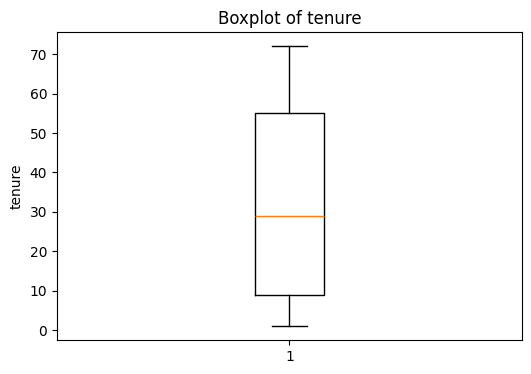

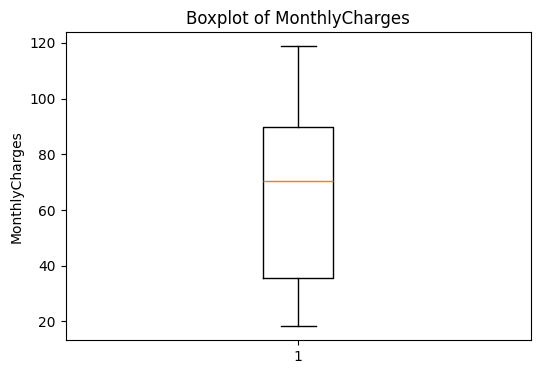

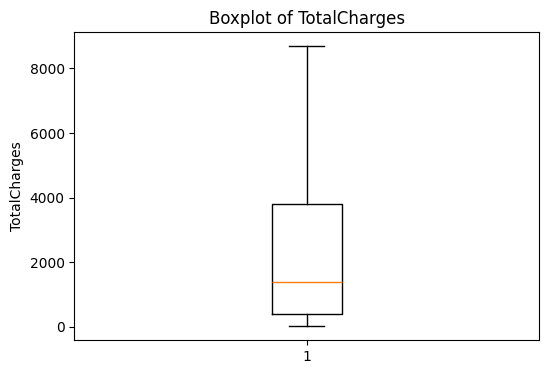

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Make sure numerical columns are actually numeric
df["tenure"] = pd.to_numeric(df["tenure"], errors="coerce")
df["MonthlyCharges"] = pd.to_numeric(df["MonthlyCharges"], errors="coerce")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Remove any rows that became missing after conversion
df = df.dropna(subset=["tenure", "MonthlyCharges", "TotalCharges"])

# Numerical features
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]

# Draw boxplots
for column in numeric_features:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[column])
    plt.title(f"Boxplot of {column}")
    plt.ylabel(column)
    plt.show()
    plt.show()

## 4.5 Identification of Numerical and Categorical Features

The features are divided into numerical and categorical variables based on their data types.

Numerical variables contain quantitative values, while categorical variables contain labels or categories. Categorical variables will require encoding before being used by machine learning models.

In [ ]:
# Identify numerical and categorical features

numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = df.select_dtypes(
    include=["object"]
).columns.tolist()

# Remove target variable from categorical features
categorical_features.remove("Churn")

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 4.6 Separating Features and Target

The dataset is divided into independent variables (`X`) and the dependent variable (`y`).

- `X` contains the customer-related features used to predict churn.
- `y` contains the target variable `Churn`.

The `customerID` column has already been removed because it is only a unique identifier.

In [ ]:
# Separate features and target

X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (7032, 19)
Shape of y: (7032,)


## 4.7 Train-Test Split

The dataset is divided into training and testing sets.

The training set is used to train the machine learning model, while the testing set is used to evaluate the model on unseen data.

An 80:20 split is used. Stratification is applied to maintain a similar proportion of churned and non-churned customers in both sets.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (5625, 19)
Testing set shape: (1407, 19)


## 4.8 Encoding and Feature Scaling

The dataset contains both numerical and categorical features.

Categorical features are converted into numerical form using One-Hot Encoding. Numerical features are standardized using StandardScaler so that features with different ranges are placed on a comparable scale.

A ColumnTransformer is used to apply the appropriate preprocessing to each type of feature.

The preprocessing is fitted only on the training data to prevent data leakage from the test set.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical features
numerical_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Categorical features
categorical_features = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


# 5. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the distribution of the data and identify relationships between customer characteristics and churn.

The analysis focuses on the target variable and important numerical and categorical features to identify patterns that may help in predicting customer churn.

## 5.1 Churn Distribution

The distribution of the target variable `Churn` is examined to understand the proportion of customers who churned and those who remained with the telecom service.

Churn
No     5163
Yes    1869
Name: count, dtype: int64


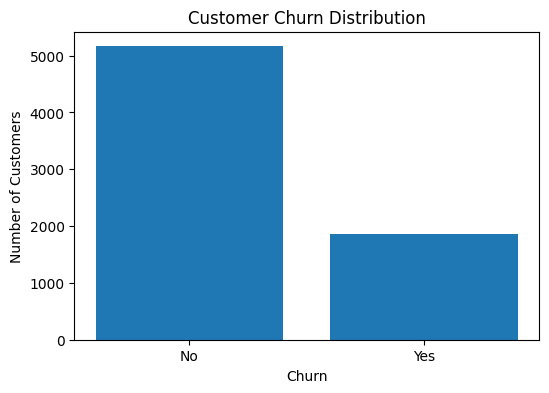

In [ ]:
import matplotlib.pyplot as plt

# Count churn classes
churn_counts = df["Churn"].value_counts()

print(churn_counts)

# Plot churn distribution
plt.figure(figsize=(6, 4))
plt.bar(churn_counts.index, churn_counts.values)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

## 5.2 Churn by Contract Type

The relationship between contract type and customer churn is examined. This helps determine whether customers with different contract durations have different churn behaviour.

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.722826  11.277174
Two year        97.151335   2.848665


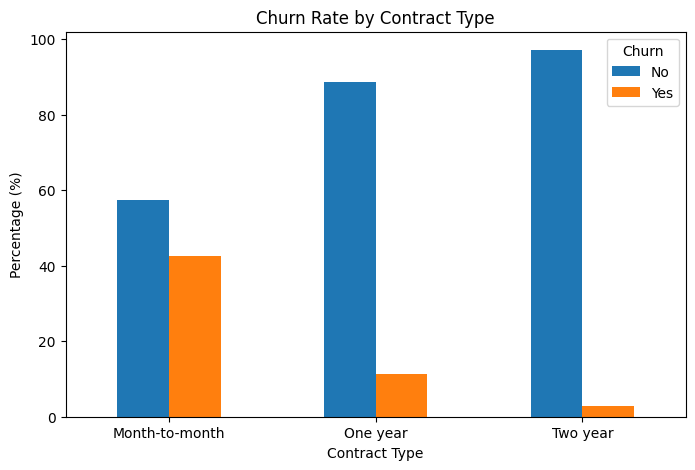

In [ ]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn)

contract_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

## 5.3 Churn by Tenure

Customer tenure is analysed to determine whether the length of time a customer has been with the telecom company is associated with churn.

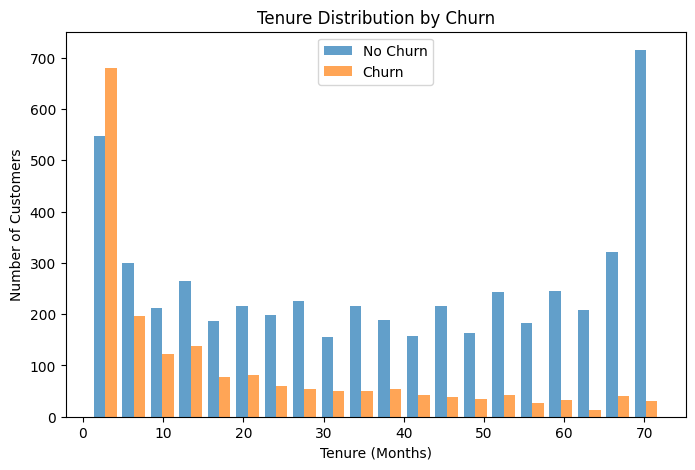

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    [df[df["Churn"] == "No"]["tenure"],
     df[df["Churn"] == "Yes"]["tenure"]],
    bins=20,
    label=["No Churn", "Churn"],
    alpha=0.7
)

plt.title("Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.legend()
plt.show()

## 5.4 Churn by Monthly Charges

Monthly charges are analysed to determine whether customers paying higher monthly charges show different churn behaviour compared with customers paying lower charges.

/tmp/ipykernel_1733/2908407004.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


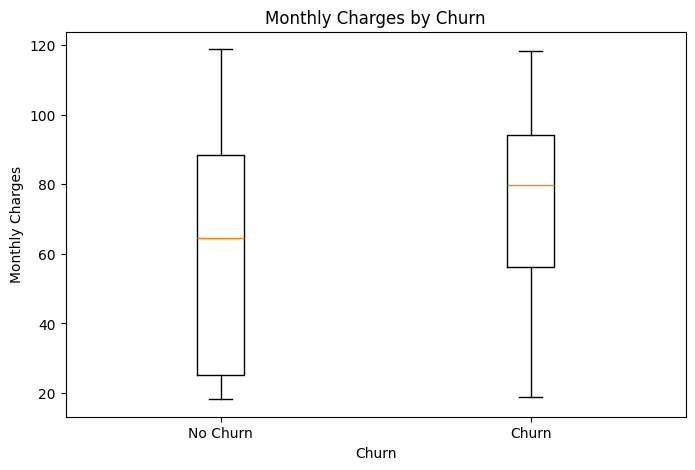

In [ ]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df[df["Churn"] == "No"]["MonthlyCharges"],
        df[df["Churn"] == "Yes"]["MonthlyCharges"]
    ],
    labels=["No Churn", "Churn"]
)

plt.title("Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

## 5.5 Churn by Internet Service

The relationship between internet service type and customer churn is examined to identify whether customers using different internet services exhibit different churn rates.

Churn                   No        Yes
InternetService                      
DSL              81.001656  18.998344
Fiber optic      58.107235  41.892765
No               92.565789   7.434211


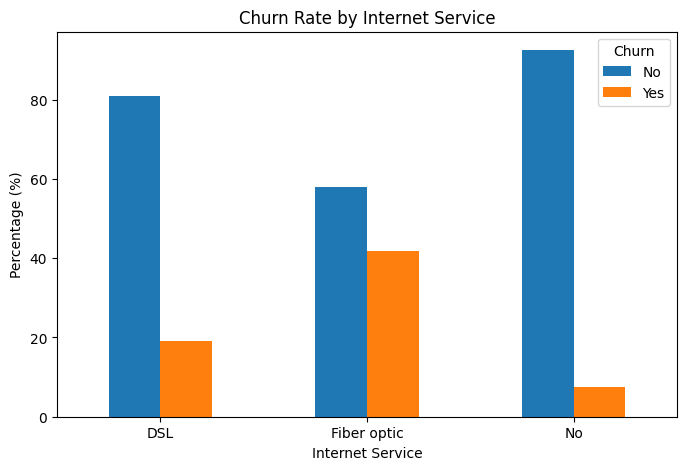

In [ ]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn)

internet_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

# 6. Feature Selection

Feature selection is performed to identify the variables that provide useful information for predicting customer churn.

The `customerID` column has already been excluded because it is only an identifier and does not contain predictive information. The remaining features are considered for model development based on their relevance to the target variable `Churn`.

In [ ]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Number of selected features:", X.shape[1])
print("\nSelected features:")
print(X.columns.tolist())

Number of selected features: 19

Selected features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


### 6.1 Numerical and Categorical Features

The selected features are divided into numerical and categorical variables. Numerical features contain quantitative values, while categorical features contain labels or categories. This distinction is important because categorical variables need to be encoded before they can be used by machine learning algorithms.

In [ ]:
# Identify numerical and categorical features

numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### 6.2 Feature Relevance Analysis

The numerical features are examined for their relationship with the target variable. This helps identify whether numerical variables contain useful predictive information for customer churn.

Categorical features are retained because variables such as contract type, internet service, and payment method may contain important information about customer churn.

In [ ]:
# Convert target variable to numerical form for correlation analysis

y_numeric = y.map({"No": 0, "Yes": 1})

# Correlation of numerical features with churn

correlation = X[numerical_features].corrwith(y_numeric).sort_values(
    key=abs, ascending=False
)

print("Correlation of numerical features with Churn:")
print(correlation)

Correlation of numerical features with Churn:
tenure           -0.354049
TotalCharges     -0.199484
MonthlyCharges    0.192858
SeniorCitizen     0.150541
dtype: float64


# 7. Model Building

Since the objective is to predict whether a customer will churn or not, this is a binary classification problem.

The dataset is divided into training and testing sets. The categorical features are encoded and numerical features are scaled before training the classification models.

Multiple classification algorithms are considered so that their performance can be compared and the most suitable model can be selected.

### 7.1 Train-Test Split

The dataset is divided into training and testing subsets using an 80:20 ratio.

The training data is used to learn the patterns in the dataset, while the testing data is kept unseen during training and is used to evaluate how well the model generalizes to new customers.

Stratified splitting is used to preserve the proportion of churned and non-churned customers in both datasets.

In [ ]:
from sklearn.model_selection import train_test_split

# Split features and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training data shape: (5625, 19)
Testing data shape: (1407, 19)

Training target distribution:
Churn
No     0.734222
Yes    0.265778
Name: proportion, dtype: float64

Testing target distribution:
Churn
No     0.734186
Yes    0.265814
Name: proportion, dtype: float64


### 7.2 Data Preprocessing

The dataset contains both numerical and categorical features.

Numerical features are standardized using `StandardScaler` so that they have a comparable scale.

Categorical features are converted into numerical representations using One-Hot Encoding. The `handle_unknown="ignore"` option ensures that previously unseen categories in the test data do not cause errors.

A `ColumnTransformer` is used to apply the appropriate preprocessing technique to each type of feature.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocessing for numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created successfully.")

Numerical features: 4
Categorical features: 15
Preprocessing pipeline created successfully.


### 7.3 Training Multiple Classification Models

To determine which algorithm is most suitable for customer churn prediction, multiple classification models are developed.

The following models are considered:

- Logistic Regression – provides a simple and interpretable baseline.
- Decision Tree Classifier – captures non-linear relationships and is easy to interpret.
- Random Forest Classifier – combines multiple decision trees to improve predictive performance and reduce overfitting.

All models use the same preprocessing pipeline to ensure a fair comparison.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Train Logistic Regression using the existing preprocessing pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Decision Tree pipeline
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

# Random Forest pipeline
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# Train Decision Tree
decision_tree_model.fit(X_train, y_train)

# Train Random Forest
random_forest_model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")
print("Random Forest model trained successfully.")

Decision Tree model trained successfully.
Random Forest model trained successfully.


### 7.4 Prediction on Test Data

After training, each model is used to predict the churn status of customers in the unseen testing dataset.

These predictions will later be used to evaluate and compare the performance of the models using different classification metrics.

In [ ]:
# Generate predictions for all models

y_pred_logistic = logistic_model.predict(X_test)
y_pred_tree = decision_tree_model.predict(X_test)
y_pred_forest = random_forest_model.predict(X_test)

print("Predictions generated successfully.")

print("\nLogistic Regression predictions:")
print(y_pred_logistic[:10])

print("\nDecision Tree predictions:")
print(y_pred_tree[:10])

print("\nRandom Forest predictions:")
print(y_pred_forest[:10])

Predictions generated successfully.

Logistic Regression predictions:
['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No']

Decision Tree predictions:
['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No']

Random Forest predictions:
['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No']


# 8. Model Evaluation

The trained machine learning models are evaluated using the testing dataset.

Since customer churn is a binary classification problem, different evaluation metrics are used to measure the performance of the models.

The main metrics used are:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix
- ROC-AUC

Using multiple metrics provides a more complete evaluation than accuracy alone.

## 8.1 Generating Predictions

The trained models are used to predict whether customers in the testing dataset will churn or not.

In [ ]:
# Generate predictions

y_pred_logistic = logistic_model.predict(X_test)
y_pred_tree = decision_tree_model.predict(X_test)
y_pred_forest = random_forest_model.predict(X_test)

print("Predictions generated successfully.")

Predictions generated successfully.


## 8.2 Accuracy

Accuracy represents the proportion of total predictions that were classified correctly.

It provides an overall measure of how often the model makes the correct prediction.

In [ ]:
from sklearn.metrics import accuracy_score

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_logistic))

print("Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred_tree))

print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_forest))

Logistic Regression Accuracy: 0.8038379530916845
Decision Tree Accuracy: 0.7896233120113717
Random Forest Accuracy: 0.7874911158493249


## 8.3 Precision, Recall and F1-Score

Accuracy alone may not provide enough information because the dataset contains more customers who did not churn than customers who churned.

Therefore, precision, recall and F1-score are also considered.

- Precision measures how many customers predicted as churners actually churned.
- Recall measures how many of the actual churners were correctly identified.
- F1-score provides a balance between precision and recall.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_forest
}

for name, predictions in models.items():

    precision = precision_score(
        y_test, predictions, pos_label="Yes"
    )

    recall = recall_score(
        y_test, predictions, pos_label="Yes"
    )

    f1 = f1_score(
        y_test, predictions, pos_label="Yes"
    )

    print("\n", name)
    print("Precision:", round(precision, 3))
    print("Recall:", round(recall, 3))
    print("F1-score:", round(f1, 3))


 Logistic Regression
Precision: 0.648
Recall: 0.572
F1-score: 0.608

 Decision Tree
Precision: 0.602
Recall: 0.615
F1-score: 0.608

 Random Forest
Precision: 0.631
Recall: 0.484
F1-score: 0.548


## 8.4 Classification Report

A classification report provides precision, recall and F1-score for each class of the target variable.

This allows the performance of the models to be examined separately for customers who churned and customers who did not churn.

In [ ]:
from sklearn.metrics import classification_report

print("Logistic Regression")
print(classification_report(y_test, y_pred_logistic))

print("\nDecision Tree")
print(classification_report(y_test, y_pred_tree))

print("\nRandom Forest")
print(classification_report(y_test, y_pred_forest))

Logistic Regression
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1033
         Yes       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407


Decision Tree
              precision    recall  f1-score   support

          No       0.86      0.85      0.86      1033
         Yes       0.60      0.61      0.61       374

    accuracy                           0.79      1407
   macro avg       0.73      0.73      0.73      1407
weighted avg       0.79      0.79      0.79      1407


Random Forest
              precision    recall  f1-score   support

          No       0.83      0.90      0.86      1033
         Yes       0.63      0.48      0.55       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.70      1407
weighted avg       0.78 

## 8.5 Confusion Matrix

A confusion matrix shows the correct and incorrect predictions made by the classification model.

It helps identify how many churn and non-churn customers were correctly or incorrectly classified.

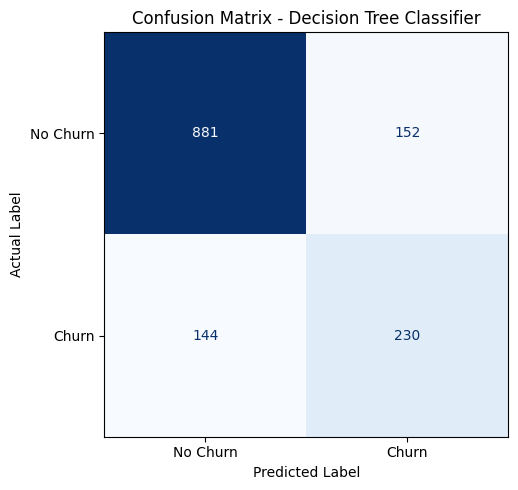

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


y_pred_dt = decision_tree_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_dt, labels=["No", "Yes"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)

ax.set_title("Confusion Matrix - Decision Tree Classifier")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.savefig(
    "decision_tree_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## 8.6 Final Model Selection

The models are compared based on their F1-score. The model with the highest F1-score is selected as the final model because F1-score provides a balance between precision and recall.

In [ ]:
from sklearn.metrics import f1_score

# Make fresh predictions
pred1 = logistic_model.predict(X_test)
pred2 = decision_tree_model.predict(X_test)
pred3 = random_forest_model.predict(X_test)

# Calculate F1-scores
score1 = f1_score(y_test, pred1, pos_label="Yes")
score2 = f1_score(y_test, pred2, pos_label="Yes")
score3 = f1_score(y_test, pred3, pos_label="Yes")

# Print scores
print("Logistic Regression F1-score:", round(score1, 3))
print("Decision Tree F1-score:", round(score2, 3))
print("Random Forest F1-score:", round(score3, 3))

# Select best model
if score1 >= score2 and score1 >= score3:
    print("\nFinal Selected Model: Logistic Regression")

elif score2 >= score1 and score2 >= score3:
    print("\nFinal Selected Model: Decision Tree")

else:
    print("\nFinal Selected Model: Random Forest")

Logistic Regression F1-score: 0.608
Decision Tree F1-score: 0.608
Random Forest F1-score: 0.548

Final Selected Model: Decision Tree


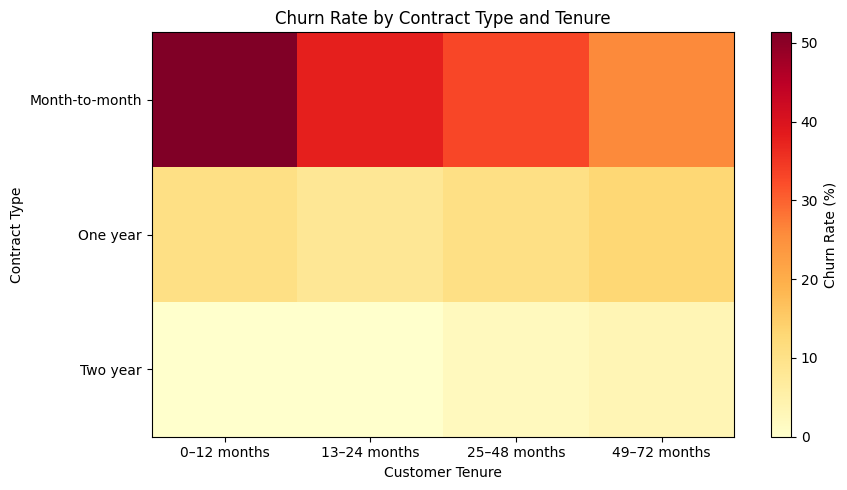

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("Telco-Customer-Churn.csv")

# Group tenure into meaningful intervals
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0–12 months", "13–24 months",
            "25–48 months", "49–72 months"]
)

# Calculate churn percentage for each combination
heatmap_data = pd.crosstab(
    [df["Contract"], df["TenureGroup"]],
    df["Churn"],
    normalize="index"
) * 100

churn_rates = heatmap_data["Yes"].unstack()

plt.figure(figsize=(9, 5))
plt.imshow(churn_rates, aspect="auto", cmap="YlOrRd")

plt.xticks(range(len(churn_rates.columns)), churn_rates.columns)
plt.yticks(range(len(churn_rates.index)), churn_rates.index)
plt.xlabel("Customer Tenure")
plt.ylabel("Contract Type")
plt.title("Churn Rate by Contract Type and Tenure")

plt.colorbar(label="Churn Rate (%)")
plt.tight_layout()
plt.savefig("contract_tenure_churn_heatmap.png", dpi=300,
            bbox_inches="tight")
plt.show()

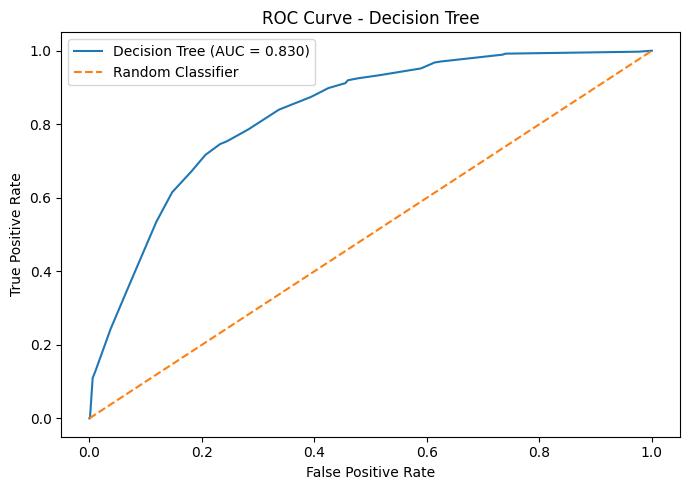

Decision Tree ROC-AUC: 0.83


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_test_binary = (y_test == "Yes").astype(int)
y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test_binary, y_prob_tree)
auc_value = roc_auc_score(y_test_binary, y_prob_tree)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Decision Tree (AUC = {auc_value:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Decision Tree")
plt.legend()
plt.tight_layout()
plt.savefig("decision_tree_roc_curve.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Decision Tree ROC-AUC:", round(auc_value, 3))

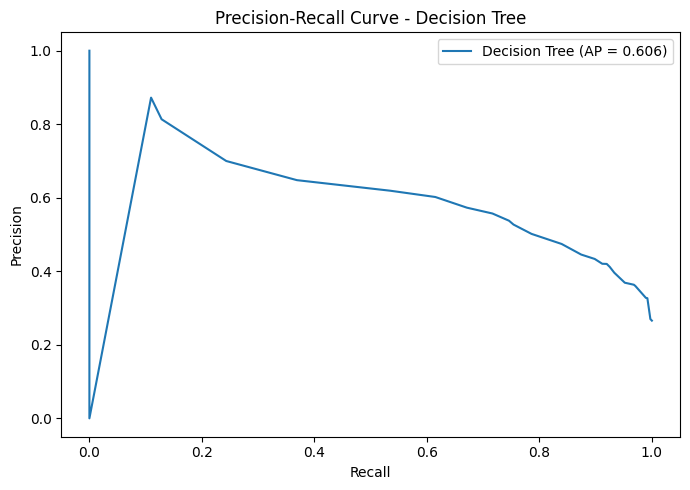

Decision Tree Average Precision: 0.606


In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

precision_values, recall_values, _ = precision_recall_curve(
    y_test_binary, y_prob_tree
)

ap_score = average_precision_score(y_test_binary, y_prob_tree)

plt.figure(figsize=(7, 5))
plt.plot(recall_values, precision_values,
         label=f"Decision Tree (AP = {ap_score:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Decision Tree")
plt.legend()
plt.tight_layout()
plt.savefig("decision_tree_precision_recall.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Decision Tree Average Precision:", round(ap_score, 3))

# 9. Interpretation of Results

The results obtained from the machine learning models are interpreted to understand their performance and the important factors related to customer churn.

The interpretation focuses on:
- Comparing model performance
- Understanding important churn patterns
- Identifying the best-performing model
- Drawing useful business insights

## 9.1 Model Performance Comparison

The performance of the classification models is compared using accuracy, precision, recall and F1-score.

A higher value generally indicates better performance for the corresponding metric.

In [ ]:
# Display model performance

print("Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, y_pred_logistic), 3))
print("F1-score:", round(f1_score(y_test, y_pred_logistic, pos_label="Yes"), 3))

print("\nDecision Tree")
print("Accuracy:", round(accuracy_score(y_test, y_pred_tree), 3))
print("F1-score:", round(f1_score(y_test, y_pred_tree, pos_label="Yes"), 3))

print("\nRandom Forest")
print("Accuracy:", round(accuracy_score(y_test, y_pred_forest), 3))
print("F1-score:", round(f1_score(y_test, y_pred_forest, pos_label="Yes"), 3))

Logistic Regression
Accuracy: 0.804
F1-score: 0.608

Decision Tree
Accuracy: 0.79
F1-score: 0.608

Random Forest
Accuracy: 0.787
F1-score: 0.548


## 9.2 Important Factors Affecting Churn

The exploratory analysis identified several factors that are associated with customer churn.

The important observations include:

- Month-to-month contract customers have a higher churn rate.
- Customers with shorter tenure are more likely to churn.
- Customers with higher monthly charges show a higher tendency to churn.
- Fiber optic customers show comparatively higher churn.
- Customers with longer-term contracts are less likely to churn.

In [ ]:
# Check churn rate by contract type

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


## 9.3 Highest Churn Contract Type

The churn rate for each contract type is compared to identify which type of contract has the highest percentage of customers leaving.

This helps the telecom company identify customers who may be at greater risk of churn and take suitable retention measures.


In [ ]:
# Find the contract type with the highest churn rate

highest_churn_contract = contract_churn["Yes"].idxmax()

print("Contract type with highest churn:", highest_churn_contract)
print("Churn rate:",
      round(contract_churn["Yes"].max(), 2), "%")

Contract type with highest churn: Month-to-month
Churn rate: 42.71 %


## 9.4 Business Interpretation

The model results and exploratory analysis provide useful insights for telecom companies.

Customers on month-to-month contracts are more likely to churn, so the company can encourage such customers to move to longer-term contracts.

Customers with shorter tenure should be given special attention because they have a higher probability of leaving.

Customers with higher monthly charges may also require targeted offers or discounts.

The company can use the churn prediction model to identify customers who are more likely to leave and take preventive actions such as personalised offers, discounts, improved support and contract incentives.

## 9.5 Final Interpretation

The machine learning models were able to predict customer churn using customer demographic, service, contract and billing information.

The evaluation results show differences in the performance of Logistic Regression, Decision Tree and Random Forest.

The model with the best overall F1-score is considered the most suitable final model for this project.

The analysis also shows that contract type, tenure, monthly charges and internet service are important factors associated with customer churn.

These results can help telecom companies identify customers at risk of churn and take suitable retention measures.

### Project Conclusion

The project successfully developed a machine learning approach for predicting telecom customer churn. The analysis identified important churn patterns, compared multiple classification models, and selected a final model based on F1-score. The results can help telecom companies identify customers at risk of leaving and support customer retention strategies.

# 10. Flow Diagram

The following flow diagram represents the complete workflow followed in the customer churn prediction project, from defining the problem to interpreting the final model results.

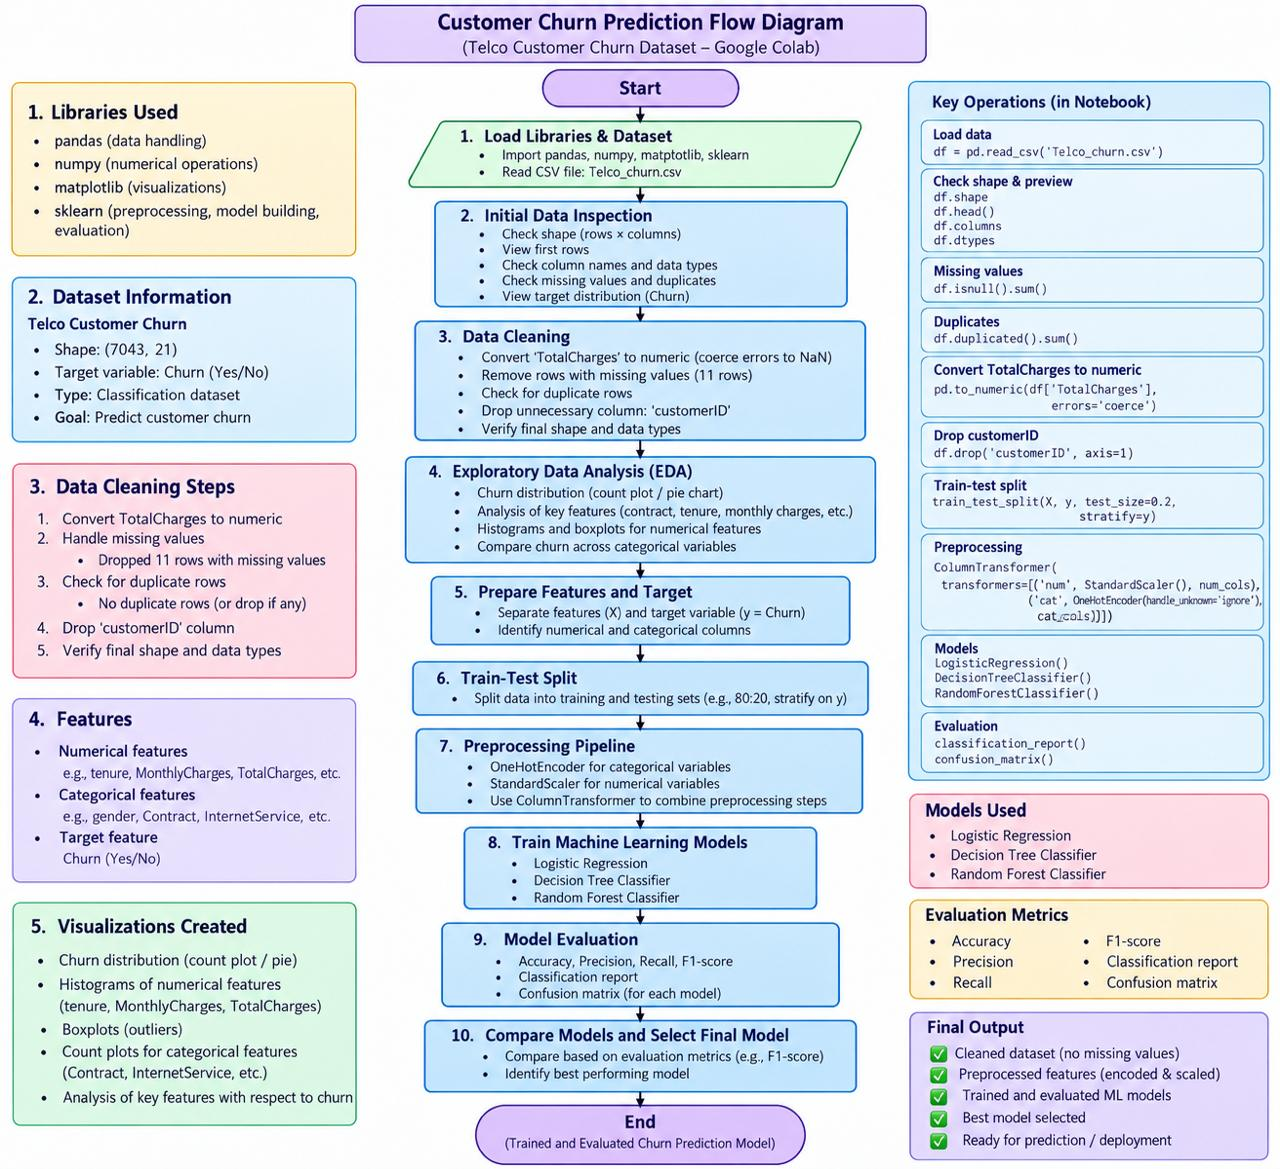

In [ ]:

from IPython.display import display, Image

display(Image(filename='/content/churnflow.jpeg'))
